# Kernel PCA: scikit-learn vs Moxie

**Reference example:** `../scikit-learn/examples/decomposition/plot_kernel_pca.py` at scikit-learn
`4358542a1bd39af2e7e1cbace8b9fed067473c5b`
([rendered gallery page](https://scikit-learn.org/dev/auto_examples/decomposition/plot_kernel_pca.html)).

**Scenario:** two concentric circles (`make_circles(n_samples=1_000, factor=0.3, noise=0.05, random_state=0)`),
split 750/250 with `train_test_split(stratify=y, random_state=0)`. `PCA(n_components=2)` and
`KernelPCA(n_components=None, kernel="rbf", gamma=10, fit_inverse_transform=True, alpha=0.1)` are fitted on
the training part; the test part is projected and reconstructed with `inverse_transform`.

**Adaptations:**
- Data generation and the split stay in Python (sklearn's `make_circles` / `train_test_split`); the arrays are
  shared with Mojo, which does all fitting, projection and reconstruction.
- Figures are reduced (dpi 70) and the training/testing scatter is merged with the projection figure.
- Extra check (not in the gallery script): the `eigenvalues_`, the kept component count, `gamma_`,
  `get_feature_names_out` and the projection of the training data (`fit_transform`).

**Determinism:** deterministic. `make_circles` and the split are seeded and both libraries use an exact dense
eigensolver for `eigen_solver="auto"` here (sklearn picks `dense` because `n_components=None`). Kernel PCA
eigenvectors are unique only up to sign (fixed by `svd_flip` in both) and within degenerate eigenspaces, so
values are compared component by component on the leading, well-separated components (see the tolerances).

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "notebooks/_support/moxie_nb.py").exists())
sys.path.insert(0, str(ROOT / "notebooks/_support"))
%load_ext moxie_nb
nb = moxie_nb.Session("decomposition/plot_kernel_pca")

## 1. scikit-learn (Python reference)

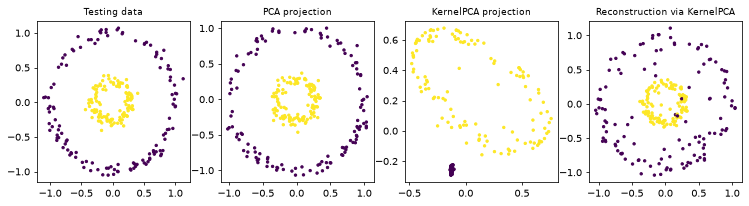

kept components: 368 | leading eigenvalues: [81.10182653 75.01266248 73.70019127 32.97104177 31.86002697 31.7265732 ]


In [2]:
import matplotlib.pyplot as plt
import numpy as np

from sklearn.datasets import make_circles
from sklearn.model_selection import train_test_split

X, y = make_circles(n_samples=1_000, factor=0.3, noise=0.05, random_state=0)
X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, random_state=0)

from sklearn.decomposition import PCA, KernelPCA

pca = PCA(n_components=2)
kernel_pca = KernelPCA(
    n_components=None, kernel="rbf", gamma=10, fit_inverse_transform=True, alpha=0.1
)

X_test_pca = pca.fit(X_train).transform(X_test)
X_test_kernel_pca = kernel_pca.fit(X_train).transform(X_test)

X_reconstructed_pca = pca.inverse_transform(pca.transform(X_test))
X_reconstructed_kernel_pca = kernel_pca.inverse_transform(kernel_pca.transform(X_test))

fig, axes = plt.subplots(ncols=4, figsize=(13, 3), dpi=70)
axes[0].scatter(X_test[:, 0], X_test[:, 1], c=y_test, s=6); axes[0].set_title("Testing data", fontsize=9)
axes[1].scatter(X_test_pca[:, 0], X_test_pca[:, 1], c=y_test, s=6); axes[1].set_title("PCA projection", fontsize=9)
axes[2].scatter(X_test_kernel_pca[:, 0], X_test_kernel_pca[:, 1], c=y_test, s=6)
axes[2].set_title("KernelPCA projection", fontsize=9)
axes[3].scatter(X_reconstructed_kernel_pca[:, 0], X_reconstructed_kernel_pca[:, 1], c=y_test, s=6)
axes[3].set_title("Reconstruction via KernelPCA", fontsize=9)
plt.show()

sk = {"train_kpca": kernel_pca.transform(X_train), "eigenvalues": kernel_pca.eigenvalues_,
      "names": kernel_pca.get_feature_names_out()}
print("kept components:", kernel_pca.eigenvalues_.shape[0], "| leading eigenvalues:", kernel_pca.eigenvalues_[:6])
nb.share(X_train=X_train, X_test=X_test)

## 2. Moxie (native Mojo)

The same scenario through `moxie.decomposition.PCA` and `KernelPCA`; Python only supplies the data files.

In [3]:
%%mojo kernel_pca
from moxie.decomposition import PCA, KernelPCA
from moxie_nb_io import load, save, save_floats, save_strings


def main() raises:
    var X_train = load("X_train")
    var X_test = load("X_test")
    var pca = PCA(n_components=2)
    var kernel_pca = KernelPCA(n_components=None, kernel="rbf", gamma=10.0, fit_inverse_transform=True, alpha=0.1)
    var X_test_pca = pca.fit(X_train).transform(X_test)
    var X_test_kernel_pca = kernel_pca.fit(X_train).transform(X_test)
    save("X_test_pca", X_test_pca)
    save("X_test_kernel_pca", X_test_kernel_pca)
    save("X_reconstructed_pca", pca.inverse_transform(pca.transform(X_test)))
    save("X_reconstructed_kernel_pca", kernel_pca.inverse_transform(kernel_pca.transform(X_test)))
    save("train_kpca", kernel_pca.transform(X_train))
    save("eigenvalues", kernel_pca.eigenvalues_.value())
    save_floats("gamma", [kernel_pca.gamma_])
    save_strings("names", kernel_pca.get_feature_names_out())
    print("kept components:", kernel_pca.eigenvalues_.value().shape[0])

kept components: 368


## 3. Side by side and parity

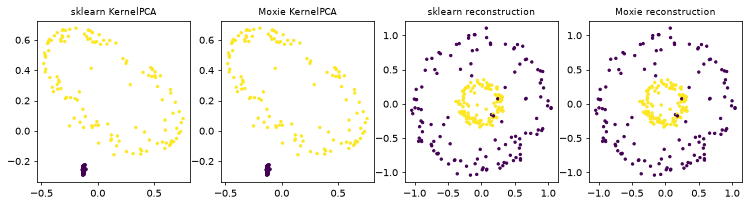

relative gaps between the leading eigenvalues: [0.07508 0.01618 0.5022  0.0137  0.00165 0.00305 0.01945 0.02805]


check,status,sklearn shape,moxie shape,max |diff|,max rel,tolerance,detail,tolerance reason
PCA transform (X_test_pca),PASS,"(250, 2)","(250, 2)",2.43e-14,8.04e-11,"rtol=1e-09, atol=1e-11",,"exact SVD of a 750x2 matrix; rounding only, same svd_flip rule"
PCA inverse_transform,PASS,"(250, 2)","(250, 2)",4.44e-16,4.2e-15,"rtol=1e-09, atol=1e-11",,exact for two components; rounding only
gamma_,PASS,(),(),,,exact,0 mismatches,
kept component count (n_components=None),PASS,(),(),,,exact,0 mismatches,
eigenvalues_ (leading 20),PASS,"(20,)","(20,)",5.54e-13,7.7e-15,"rtol=1e-09, atol=8.11018e-08",,dense symmetric eigensolver on a 750x750 centered rbf kernel (Jacobi vs LAPACK syevr); absolute rounding ~ n * eps * largest eigenvalue
"KernelPCA transform, leading 4 components",PASS,"(250, 4)","(250, 4)",7.79e-14,7.98e-12,"rtol=1e-06, atol=1e-08",,eigenvectors of separated eigenvalues (relative gaps above 1e-3) are determined to ~eps*||K||/gap; svd_flip fixes the sign
"KernelPCA fit data transform, leading 4 components",PASS,"(750, 4)","(750, 4)",7.84e-14,1.31e-10,"rtol=1e-06, atol=1e-08",,as above
KernelPCA inverse_transform (reconstruction),PASS,"(250, 2)","(250, 2)",1.19e-11,6.57e-11,"rtol=1e-06, atol=1e-08",,"the learned pre-image map is a kernel ridge on the projected training points; rbf distances are invariant to rotations inside degenerate eigenspaces, so the result is well defined"
get_feature_names_out (leading 3),PASS,"(3,)","(3,)",,,exact,0 mismatches,
train/test scatter figures,ADAPTED,,,,,,merged into one reduced figure; plotting only,


In [4]:
mx = nb.results["kernel_pca"]
moxie_nb.side_by_side(sklearn=X_test_kernel_pca[:5, :3], moxie=mx["X_test_kernel_pca"][:5, :3])
fig, axes = plt.subplots(ncols=4, figsize=(13, 3), dpi=70)
for k, (title, data) in enumerate([("sklearn KernelPCA", X_test_kernel_pca), ("Moxie KernelPCA", mx["X_test_kernel_pca"]),
                                   ("sklearn reconstruction", X_reconstructed_kernel_pca),
                                   ("Moxie reconstruction", mx["X_reconstructed_kernel_pca"])]):
    axes[k].scatter(data[:, 0], data[:, 1], c=y_test, s=6); axes[k].set_title(title, fontsize=9)
plt.show()

ev_sk, ev_mx = kernel_pca.eigenvalues_, mx["eigenvalues"]
gaps = np.abs(np.diff(ev_sk[:12])) / ev_sk[0]
lead = 4
print("relative gaps between the leading eigenvalues:", np.round(gaps[:8], 5))
nb.compare("PCA transform (X_test_pca)", X_test_pca, mx["X_test_pca"], rtol=1e-9, atol=1e-11,
           reason="exact SVD of a 750x2 matrix; rounding only, same svd_flip rule")
nb.compare("PCA inverse_transform", X_reconstructed_pca, mx["X_reconstructed_pca"], rtol=1e-9, atol=1e-11,
           reason="exact for two components; rounding only")
nb.compare("gamma_", 10.0, mx["gamma"][0], exact=True)
nb.compare("kept component count (n_components=None)", ev_sk.shape[0], ev_mx.shape[0], exact=True)
k = min(ev_sk.shape[0], ev_mx.shape[0])
nb.compare("eigenvalues_ (leading 20)", ev_sk[:20], ev_mx[:20], rtol=1e-9, atol=1e-9 * ev_sk[0],
           reason="dense symmetric eigensolver on a 750x750 centered rbf kernel (Jacobi vs LAPACK syevr); "
                  "absolute rounding ~ n * eps * largest eigenvalue")
nb.compare(f"KernelPCA transform, leading {lead} components", X_test_kernel_pca[:, :lead], mx["X_test_kernel_pca"][:, :lead],
           rtol=1e-6, atol=1e-8,
           reason="eigenvectors of separated eigenvalues (relative gaps above 1e-3) are determined to "
                  "~eps*||K||/gap; svd_flip fixes the sign")
nb.compare(f"KernelPCA fit data transform, leading {lead} components", sk["train_kpca"][:, :lead], mx["train_kpca"][:, :lead],
           rtol=1e-6, atol=1e-8, reason="as above")
nb.compare("KernelPCA inverse_transform (reconstruction)", X_reconstructed_kernel_pca, mx["X_reconstructed_kernel_pca"],
           rtol=1e-6, atol=1e-8,
           reason="the learned pre-image map is a kernel ridge on the projected training points; rbf distances "
                  "are invariant to rotations inside degenerate eigenspaces, so the result is well defined")
nb.compare("get_feature_names_out (leading 3)", sk["names"][:3], mx["names"][:3], exact=True)
nb.note("train/test scatter figures", "ADAPTED", "merged into one reduced figure; plotting only")
nb.report()
nb.assert_parity()